# INTRODUCCIÓN: CONCEPTOS BÁSICOS SOBRE DIAGNÓSTICO DEL CÁNCER DE MAMA

El cáncer de mama es un tipo de cáncer que se origina en el tejido mamario debido al crecimiento anormal de células. El cáncer de mama puede darse tanto en hombres como en mujeres.

Clasificaciones para describir el estado de la enfermedad de cáncer de mama:

1) El TNM, que es el sistema estándar internacional para describir la exténsión anatómica del cáncer. En cáncer de mama, las letras significan:

- T (Tumor): tamaño y extensión del tumor primario --> Columna: 'T Stage' y 'Tumor Size'
- N (Nodes): afectación de ganglios linfáticos regionales --> Columna: 'N Stage'
- M (Metastasis): presencia o ausencia de metástasis a distancia. 

2) 6th Stage, que es el estadio clínico del cáncer de mama según la clasificación AJCC (6.ª edición), que refleja el grado de extensión de la enfermedad.

3) Grado de diferenciación tumoral, que explica cuanto se parecen las células cancerígenas a las células mamarias normales --> Columnas: 'Grade' y 'differentiate'.

4) A Stage, que en este dataset define la localización del tumor, es decir, cuánto se ha extendido el tumor. 

5) Estrogen Status y Progesterone Status, indican si el cácer de mama está relacionado hormonalmente o no. Se utiliza para poner el tratamiento al paciente.

6) Regional Node Examined and Regional Node Positive, indican cuántos gánglios linfáticos regionales fueron examinados y cuántos de ellos dieron positivo.


Relaciones entre variables:

Relación TNM y Tumor Size:

| T Stage   | Tumor Size    | N Stage   | M | 
| ---   | ---   | ---   | ---   | 
| T1    | <= 2 cm   | N0    | M0    | 
| T1    | <= 2 cm   | N1    | M0    |
| T2    | > 2 <= 5 cm   | N0    | M0    | 
| T2    | > 2 <= 5 cm   | N1    | M0    | 
| T3    | > 5 cm    | N0 - N1   | M0    |
| T1 - T3   | Cualquier | N2 - N3   | M0    |
| T4    | Invasión de piel o pared torácica | Cualquier | M0    | 
| Cualquiera    | Cualquier | Cualquier | M1    | 

El mejor pronóstico de la enfermedad es cuanto menor sean todos los parámetros anteriores y M = 0 (ausencia de metástasis).

Relación Grade y Differenciate:

| Grade | Differenciate |
| ---   | --- |
| 1 | Well differentiated   |
| 2 | Moderately differentiated |
| 3 | Poorly differentiated |
| 4 | Undifferentiated  |

El mejor pronóstico de la enfermedad es cuanto más diferenciado (grado menor) esté el tumor.

Relación entre A Stage, N Stage y M:

| A Stage   | N Stage   | M |
| ---   | ---   | ---   |
| Localized | N0    | M0    |
| Regional  | N1 - N3   | M0    |
| Distant   | Cualquier | M1    |

El mejor pronóstico es cuanto más localizado esté el tumor.

In [ ]:
%pip install phik

In [2]:
import sys

!{sys.executable} -m pip install phik

   ---------------------------------------- 0.0/677.5 kB ? eta -:--:--
   ---------------------------------------- 677.5/677.5 kB 3.1 MB/s  0:00:00


In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os
import phik

from collections import Counter
from lightgbm import LGBMClassifier
from scipy.stats import mannwhitneyu, stats
from scipy import stats
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, SelectFromModel, RFE, SequentialFeatureSelector
from sklearn.metrics import mutual_info_score, classification_report
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from xgboost import XGBClassifier

## 1) CARGAR LOS DATOS

In [21]:
archivo = '../01 data/01 raw/Breast_Cancer.csv'
df = pd.read_csv(archivo)
df.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Age                     4024 non-null   int64
 1   Race                    4024 non-null   str  
 2   Marital Status          4024 non-null   str  
 3   T Stage                 4024 non-null   str  
 4   N Stage                 4024 non-null   str  
 5   6th Stage               4024 non-null   str  
 6   differentiate           4024 non-null   str  
 7   Grade                   4024 non-null   str  
 8   A Stage                 4024 non-null   str  
 9   Tumor Size              4024 non-null   int64
 10  Estrogen Status         4024 non-null   str  
 11  Progesterone Status     4024 non-null   str  
 12  Regional Node Examined  4024 non-null   int64
 13  Reginol Node Positive   4024 non-null   int64
 14  Survival Months         4024 non-null   int64
 15  Status                  4024 non

Este dataset no necesita ser limpiado.

## 2) EL PROBLEMA

Queremos predecir la supervivencia en meses de pacientes de cáncer de mama con carcinoma ductal infiltrante y lobulillar infiltrante, para lo cual tenemos un dataset de 4024 pacientes femeninas diagnósticadas entre 2006 y 2010. Por lo que tenemos un proyecto de Machine Learning de Regresión.

## 3) EL TARGET

In [22]:
target = df['Survival Months']

Nuestro target será la columna de Survival Months. Por consiguiente,para que no haya una fuga de información, procederé a eliminar la columna de Status, que nos indica si el paciente está vivo o no.

In [23]:
df = df.drop(columns=['Status'])

## 4) DIVIDIR EN TRAIN Y TEST

In [24]:
X_train, X_test, y_train, y_test = train_test_split(df.drop('Survival Months', axis=1),
                                                    df['Survival Months'],
                                                    test_size=0.2,
                                                    random_state=42)

In [25]:
# Guardar datos de entrenamiento
X_train.to_csv("../01 data/03 train/X_train.csv", index=False)
y_train.to_frame().to_csv("../01 data/03 train/y_train.csv", index=False)

# Guardar datos de test
X_test.to_csv("../01 data/04 test/X_test.csv", index=False)
y_test.to_frame().to_csv("../01 data/04 test/y_test.csv", index=False)

In [26]:
# Comprobación del directorio dónde se han guardado

print(os.listdir("../01 data/03 train"))
print(os.listdir("../01 data/04 test"))

['X_train.csv', 'y_train.csv']
['X_test.csv', 'y_test.csv']


## 5) EDA

5.1) EDA VARIABLE OBJETIVO

- Análisis visual: distribución, outliers

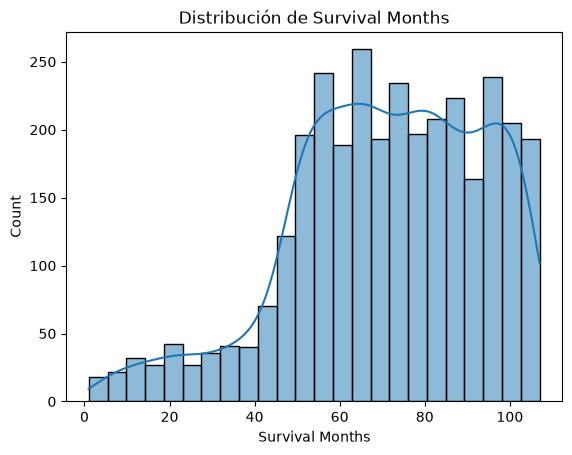

In [27]:
sns.histplot(y_train, kde=True)
plt.title("Distribución de Survival Months")
plt.show()

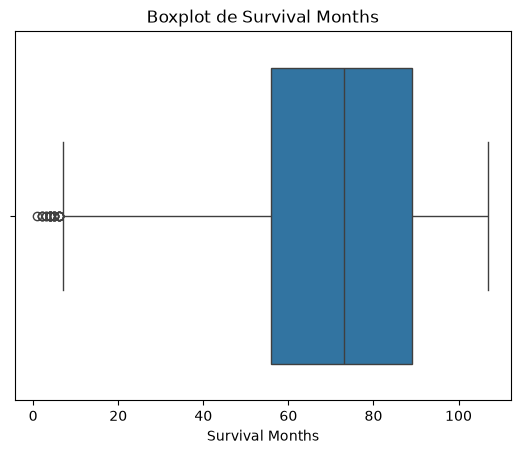

In [28]:
sns.boxplot(x=y_train)
plt.title('Boxplot de Survival Months')
plt.show()

- Análisis estadístico de la variable objetivo

In [29]:
y_train.describe()

count    3219.000000
mean       71.162162
std        22.869855
min         1.000000
25%        56.000000
50%        73.000000
75%        89.000000
max       107.000000
Name: Survival Months, dtype: float64

In [30]:
print("Media:", y_train.mean())
print("Mediana:", y_train.median())
print("Moda:", y_train.mode())
print("Varianza:", y_train.var())
print("Desviación típica:", y_train.std())
print("Coeficiente de variación:", y_train.std() / y_train.mean())
print("Asimetría:", y_train.skew())
print("Curtosis:", y_train.kurtosis())

Media: 71.16216216216216
Mediana: 73.0
Moda: 0    69
Name: Survival Months, dtype: int64
Varianza: 523.0302521290713
Desviación típica: 22.869854659115596
Coeficiente de variación: 0.3213766131360718
Asimetría: -0.5800899664045127
Curtosis: -0.0028909026993471088


La media y la mediana de la supervivencia de las pacientes es muy parecida, 71.16 meses y 73.0 meses, por lo que tiene una distribución normal.

El valor más repetido de supervivencia es de 69 meses.

Como hemos visto, la moda y la media son menores que la mediana, aunque muy parecidas, lo que quiere decir que hay una pequeña asimetría negativa hacia las pacientes con la supervivencia menor. Esto queda ratificado con el valor de asimetría de -0.58. Lo que quiere decir, es que la mayoría de las pacientes tiene supervivencias medias-altas y solo unas pocas pacientes con supervivencias mucho menores.

Tenemos una desviación típica grande, 22.87 meses respecto a la media, por lo que supone que la supervivencia de las pacientes se concentra entre los 48.3 meses y los 94 meses.

El coeficiente de variación es de 0.32, por lo que hay una variabilidad moderada-alta, por lo que la supervivencia presenta una dispersión más o menos estable.

El resultado de curtosis es negativo, -0.003, por lo que te dice una distribución con una normal más plana.

In [31]:
percentiles = y_train.quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print(percentiles)

0.01      9.0
0.05     27.0
0.10     43.0
0.25     56.0
0.50     73.0
0.75     89.0
0.90    100.0
0.95    103.0
0.99    107.0
Name: Survival Months, dtype: float64


- Detección de outliers

In [32]:
# Detección de outliers en la variable objetivo usando solo y_train

Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)

IQR = Q3 - Q1

lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

outliers = y_train[
    (y_train < lim_inf) |
    (y_train > lim_sup)
]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Límite inferior: {lim_inf:.2f}")
print(f"Límite superior: {lim_sup:.2f}")

print(f"\nNúmero de outliers: {len(outliers)}")
print(f"Porcentaje de outliers: {100 * len(outliers) / len(y_train):.2f}%")

Q1: 56.00
Q3: 89.00
IQR: 33.00
Límite inferior: 6.50
Límite superior: 138.50

Número de outliers: 24
Porcentaje de outliers: 0.75%


El análisis de percentiles muestra que la supervivencia mediana es de 73 meses. El 50% central de los pacientes presenta tiempos de supervivencia comprendidos entre 56 y 89 meses (IQR = 33 meses). Los percentiles inferiores revelan la existencia de un pequeño grupo de pacientes con supervivencias considerablemente menores (P1 = 9 meses y P5 = 27 meses), lo que genera una asimetría negativa moderada. En cambio, los percentiles superiores se encuentran muy próximos al máximo observado (P95 = 103 meses y P99 = 107 meses), indicando ausencia de valores excepcionalmente altos y una distribución relativamente estable en la cola derecha. Estos resultados son consistentes con la asimetría negativa observada previamente (skewness = -0,58) y con una curtosis prácticamente nula, sugiriendo una distribución cercana a la normalidad y sin evidencia de valores extremos severos.

- Evaluación de la normalidad

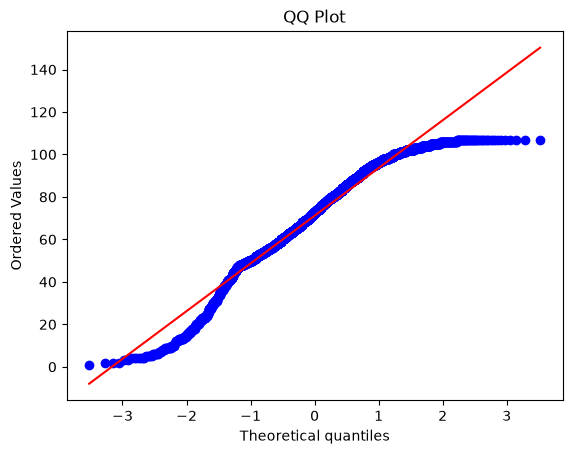

In [33]:
stats.probplot(
    y_train,
    dist="norm",
    plot=plt
)

plt.title("QQ Plot")
plt.show()

In [34]:
# Evaluación de normalidad: Test Shapiro-Wilk

from scipy.stats import shapiro

sample = y_train.sample(
    min(5000, len(y_train)),
    random_state=42
)

stat, p = shapiro(sample)

print("Estadístico:", stat)
print("p-value:", p)

if p > 0.05:
    print("No se rechaza la hipótesis de normalidad")
else:
    print("Se rechaza la hipótesis de normalidad")

Estadístico: 0.9632651711820087
p-value: 7.283486018408745e-28
Se rechaza la hipótesis de normalidad


El QQ Plot de la variable objetivo (Survival Months) muestra una clara desviación respecto a la distribución normal. Los cuantiles observados presentan una forma sigmoidal respecto a los cuantiles teóricos, especialmente en los extremos de la distribución. La cola superior muestra un efecto de truncamiento alrededor de 107 meses de supervivencia, indicando la presencia de un límite superior en los datos. Por tanto, no puede asumirse normalidad para esta variable, aunque la región central presenta un comportamiento aproximadamente lineal. Esto se confirma al realizar el test de Shapiro-Wilk, que nos dice que los datos de la variable objetivo no tienen una distribución normal.

- Transformaciones para conseguir una distribución normal en la variable objetivo

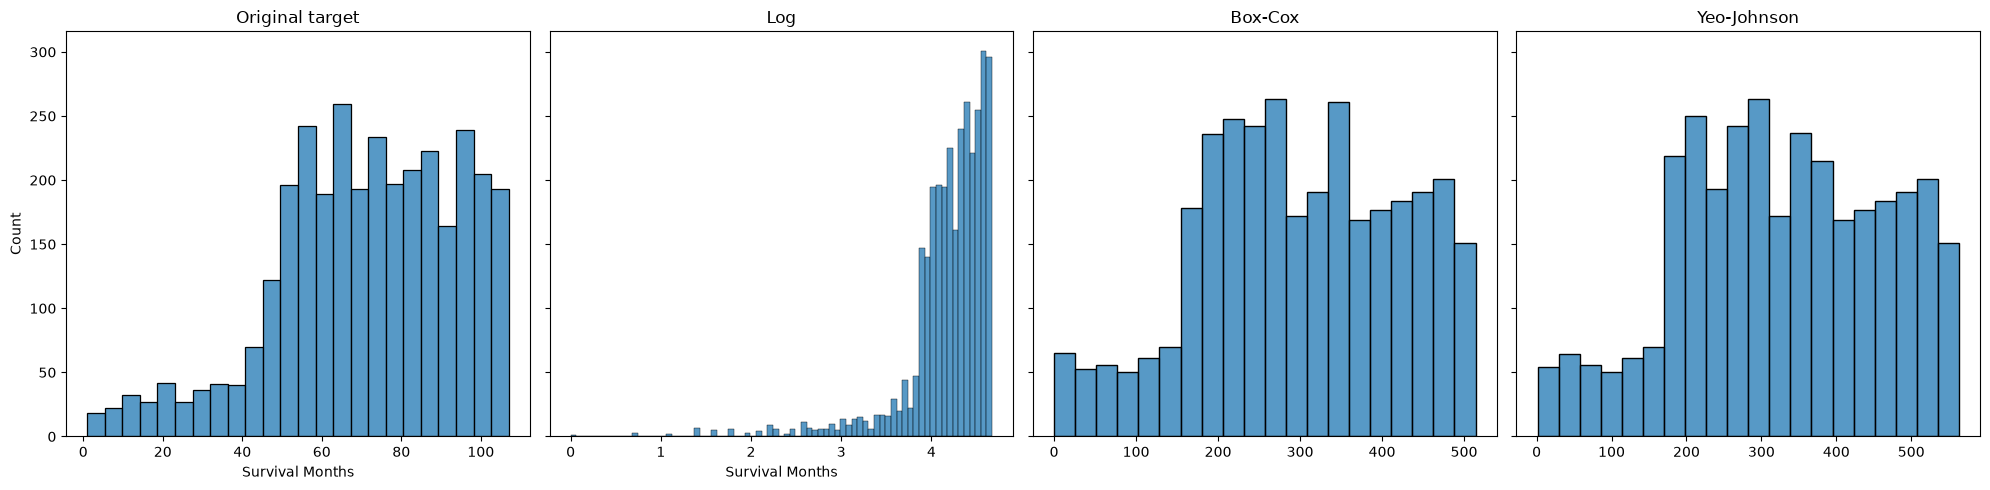

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

# Original target
sns.histplot(y_train, kde=False, ax=axes[0])
axes[0].set_title("Original target")

# Logaritmic
sns.histplot(np.log(y_train),kde=False, ax=axes[1])
axes[1].set_title("Log")

# Box-cox
sns.histplot(stats.boxcox(y_train)[0],kde=False, ax=axes[2])
axes[2].set_title("Box-Cox");

# Yeo-Johnson
pt = PowerTransformer(method='yeo-johnson', standardize=False)
y_yj = pt.fit_transform(y_train.to_numpy().reshape(-1, 1)).flatten()

sns.histplot(y_yj, kde=False, ax=axes[3])
axes[3].set_title("Yeo-Johnson")

plt.tight_layout()
plt.show()

In [36]:
y_train_log = np.log1p(y_train)

In [37]:
print("Variable original")
print("Asimetría:", y_train.skew())
print("Curtosis:", y_train.kurtosis())

print("\nTransformación log1p")
print("Asimetría:", y_train_log.skew())
print("Curtosis:", y_train_log.kurtosis())

Variable original
Asimetría: -0.5800899664045127
Curtosis: -0.0028909026993471088

Transformación log1p
Asimetría: -2.5792797437729593
Curtosis: 9.743237550556735


Evaluamos la transformación logarítmica sobre la variable objetivo, y_train, con el fin de mejorar su aproximación a una distribución normal. Sin embargo, los resultados mostraron un emperoramiento significativo en la distribución por las siguientes razones:
- La asimetría pasa de -0.58 a -2.58, pasando a tener una fuerte asimetría negativa.
- Curtosis pasó de tener un valor prácticamente de 0 a 9.74, pasando a tener una distribución muy alejada de la normalidad.

Por tanto, lo mejor es no transformar Survival Months mediante logaritmos, y continuar trabajando con la variable original.

In [38]:
from scipy.stats import boxcox

y_train_boxcox, lambda_bc = boxcox(y_train)

print("Lambda:", lambda_bc)
print("Asimetría:", pd.Series(y_train_boxcox).skew())
print("Curtosis:", pd.Series(y_train_boxcox).kurtosis())

print("Lambda Yeo-Johnson:", pt.lambdas_[0])
print("Asimetría:", stats.skew(y_yj))
print("Curtosis:", stats.kurtosis(y_yj))

Lambda: 1.4096015934258255
Asimetría: -0.20259781047886874
Curtosis: -0.6806283998857561
Lambda Yeo-Johnson: 1.4294634568638376
Asimetría: -0.1940894449548102
Curtosis: -0.6902139207850482


Se evaluaron las transformaciones Box-Cox y Yeo-Johnson sobre la variable objetivo Survival Months. Ambas redujeron significativamente la asimetría respecto a la distribución original, pasando de -0.58 a valores próximos a -0.20. Los parámetros λ obtenidos fueron muy similares (1.41 para Box-Cox y 1.43 para Yeo-Johnson), lo que indica que ambas transformaciones producen efectos prácticamente equivalentes sobre los datos. Yeo-Johnson obtuvo una ligera mejora en la reducción de la asimetría, aunque la diferencia respecto a Box-Cox fue mínima. Por tanto, puede considerarse que ambas transformaciones ofrecen un comportamiento muy similar para este conjunto de datos. Seleccionamos Box-Cox por ofrecer resultados equivalentes con una formulación más adecuada para una variable estrictamente positiva como Survival Months.

Evaluamos la aplicación de una transformación Box-Cox sobre la variable objetivo y_train con el objetivo de reducir la asimetría y aproximar la distribución a la normalidad. Obtuvimos un parámetro λ = 1,41 y consiguió reducir la asimetría de -0,58 a -0,20, acercando la distribución a una mayor simetría. Asimismo, la curtosis pasó de -0,003 a -0,68, manteniéndose dentro de valores compatibles con distribuciones de comportamiento próximo a la normalidad. Aunque la transformación Box-Cox mejora ligeramente las propiedades estadísticas de la variable objetivo, la distribución original ya presentaba una asimetría moderada y una curtosis prácticamente nula. La ganancia obtenida es limitida y no justifica la pérdida de interpretabilidad de la variable en su escala original.

5.2) EDA VARIABLES CON VARIABLE OBJETIVO

In [39]:
# Reporte de variables:

def data_report(df):
    # Sacamos los NOMBRES
    cols = pd.DataFrame(df.columns.values, columns=["COL_N"])

    # Sacamos los TIPOS
    types = pd.DataFrame(df.dtypes.values, columns=["DATA_TYPE"])

    # Sacamos los MISSINGS
    percent_missing = round(df.isnull().sum() * 100 / len(df), 2)
    percent_missing_df = pd.DataFrame(percent_missing.values, columns=["MISSINGS (%)"])

    # Sacamos los VALORES UNICOS
    unicos = pd.DataFrame(df.nunique().values, columns=["UNIQUE_VALUES"])
    
    percent_cardin = round(unicos['UNIQUE_VALUES']*100/len(df), 2)
    percent_cardin_df = pd.DataFrame(percent_cardin.values, columns=["CARDIN (%)"])

    concatenado = pd.concat([cols, types, percent_missing_df, unicos, percent_cardin_df], axis=1, sort=False)
    concatenado.set_index('COL_N', drop=True, inplace=True)


    return concatenado.T
        
data_report(X_train)

COL_N,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive
DATA_TYPE,int64,str,str,str,str,str,str,str,str,int64,str,str,int64,int64
MISSINGS (%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
UNIQUE_VALUES,40,3,5,4,3,5,4,4,2,104,2,2,53,37
CARDIN (%),1.24,0.09,0.16,0.12,0.09,0.16,0.12,0.12,0.06,3.23,0.06,0.06,1.65,1.15


Tenemos tanto variables categóricas como numéricas. No tenemos missing values en ninguna de nuestras variables, como ya se vió en el apartado de limpieza de datos, por lo que no tenemos que hacer ninguna transformación en ellas.

Tenemos las siguientes variables numéricas: Age, Tumor Size, Regional Node Examined y Regional Node Positive.

Tenemos las siguientes variables categóricas: Race, Maritas Status, T Stage, N Stage, 6Th Stage, differentiate, Grade, A Stage, Estrogen Status, Progesterone Status, Status.

- Correlación lineal variables numéricas

In [40]:
# Correlación de Pearson

train_df = X_train.copy()
train_df['Survival Months'] = y_train

corr_target = (
    train_df
    .corr(numeric_only=True)['Survival Months']
    .sort_values(ascending=False)
)

print(corr_target)

Survival Months           1.000000
Age                      -0.015292
Regional Node Examined   -0.019663
Tumor Size               -0.083942
Reginol Node Positive    -0.122360
Name: Survival Months, dtype: float64


In [41]:
# Variables más correlacionadas

corr_target.drop('Survival Months').sort_values(key=abs, ascending=False)

Reginol Node Positive    -0.122360
Tumor Size               -0.083942
Regional Node Examined   -0.019663
Age                      -0.015292
Name: Survival Months, dtype: float64

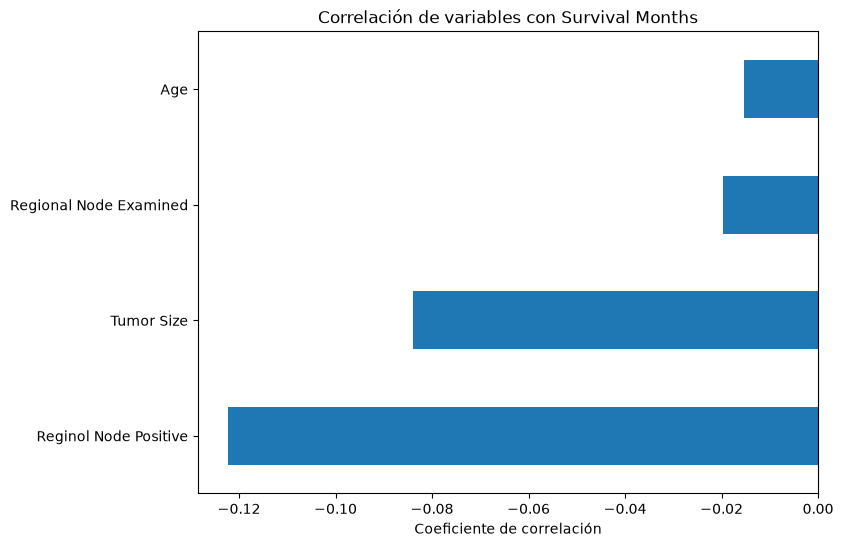

In [42]:
# Gráfico de correlaciones

plt.figure(figsize=(8,6))

corr_target.drop('Survival Months').sort_values().plot(kind='barh')

plt.title('Correlación de variables con Survival Months')
plt.xlabel('Coeficiente de correlación')
plt.show()

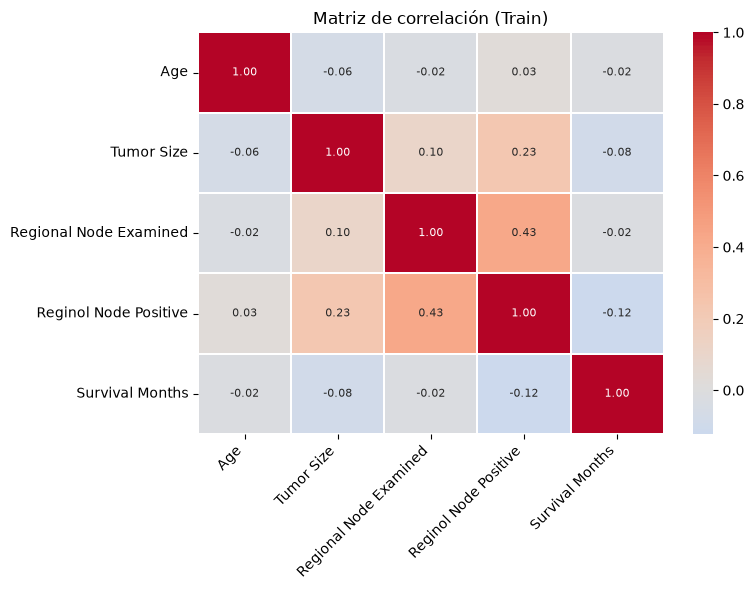

In [43]:
# Heatmap de correlaciones

plt.figure(figsize=(8, 6))

sns.heatmap(
    train_df.corr(numeric_only=True),
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 8},
    linewidths=0.3
)

plt.title('Matriz de correlación (Train)')

# Rotar etiquetas del eje X
plt.xticks(rotation=45, ha='right')

# Mantener horizontales las del eje Y
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [44]:
# Matriz de correlación de las variables predictoras
corr = X_train.corr(numeric_only=True)

features_num = X_train.select_dtypes(include=['int64', 'float64']).columns.to_list()

criterio_col = 0.7

excluidas = []

for col in features_num:

    print(f"\nVoy a comprobar la colinealidad con {col}")

    if col not in excluidas:

        for col_2, valor_corr in corr[col].items():

            print(f"Comprobando con {col_2}")

            if col == col_2:

                print("Soy yo misma, no me excluyo")

            elif col_2 in features_num:

                if abs(valor_corr) >= criterio_col:

                    print(f"Correlación = {valor_corr:.3f}, ", f"por eso excluyo a {col_2}")
                        
                    excluidas.append(col_2)

                else:
                    print(f"Correlación = {valor_corr:.3f}. ",f"Sin problemas de colinealidad.")

            else:
                print("La variable no está en la lista de variables numéricas.")

# Eliminar duplicados
excluidas = list(set(excluidas))

print("\nVariables excluidas:")
print(excluidas)


Voy a comprobar la colinealidad con Age
Comprobando con Age
Soy yo misma, no me excluyo
Comprobando con Tumor Size
Correlación = -0.062.  Sin problemas de colinealidad.
Comprobando con Regional Node Examined
Correlación = -0.024.  Sin problemas de colinealidad.
Comprobando con Reginol Node Positive
Correlación = 0.030.  Sin problemas de colinealidad.

Voy a comprobar la colinealidad con Tumor Size
Comprobando con Age
Correlación = -0.062.  Sin problemas de colinealidad.
Comprobando con Tumor Size
Soy yo misma, no me excluyo
Comprobando con Regional Node Examined
Correlación = 0.103.  Sin problemas de colinealidad.
Comprobando con Reginol Node Positive
Correlación = 0.231.  Sin problemas de colinealidad.

Voy a comprobar la colinealidad con Regional Node Examined
Comprobando con Age
Correlación = -0.024.  Sin problemas de colinealidad.
Comprobando con Tumor Size
Correlación = 0.103.  Sin problemas de colinealidad.
Comprobando con Regional Node Examined
Soy yo misma, no me excluyo
Compr

Las variables numéricas no tienen ningún problema de colinealidad entre ellas. Sin embargo, tenemos que analizar la colinealidad entre variables numéricas y categóricas.

- Estudio de variables altamente correlacionadas

In [45]:
corr_matrix = X_train.corr(numeric_only=True)

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr = [
    col
    for col in upper.columns
    if any(abs(upper[col]) > 0.7)
]

print("Variables candidatas a excluir:")
print(high_corr)

Variables candidatas a excluir:
[]


- Análisis de multicolinealidad mediante VIF

In [46]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_num = X_train.select_dtypes(include='number')

vif = pd.DataFrame({
    'Variable': X_num.columns,
    'VIF': [
        variance_inflation_factor(X_num.values, i)
        for i in range(X_num.shape[1])
    ]
})

vif.sort_values('VIF', ascending=False)


,Variable,VIF
3,Reginol Node Positive,1.280895
2,Regional Node Examined,1.223252
1,Tumor Size,1.061807
0,Age,1.007474


Tras el análisis de correlación de Pearson, se calculó el Factor de Inflación de la Varianza (Variance Inflation Factor, VIF) para las variables numéricas del conjunto de entrenamiento: Age, Tumor Size, Regional Node Examined y Reginol Node Positive.
Los valores obtenidos fueron inferiores a 1,3 en todos los casos, muy por debajo de los umbrales habitualmente utilizados para detectar problemas de multicolinealidad (VIF > 5 o VIF > 10). La variable con mayor valor fue Reginol Node Positive (VIF = 1,281), seguida de Regional Node Examined (VIF = 1,223), mientras que Tumor Size (VIF = 1,062) y Age (VIF = 1,007) mostraron una práctica independencia respecto al resto de predictores numéricos.
Estos resultados indican que no existe multicolinealidad significativa entre las variables numéricas analizadas, por lo que ninguna de ellas requiere ser eliminada por redundancia estadística antes del entrenamiento de los modelos de machine learning.

- Feature importance RandomForest

De las variables numéricas, vemos cuáles son las más importantes.

In [47]:
from sklearn.ensemble import RandomForestRegressor

In [48]:
# Seleccionar solo variables numéricas
X_train_num = X_train.select_dtypes(include=np.number)

# Entrenar Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

rf.fit(X_train_num, y_train)

# Importancia de variables
importancias = pd.DataFrame({'Feature': X_train_num.columns, 'Score': rf.feature_importances_})

# Ordenar de mayor a menor importancia
importancias = importancias.sort_values(by='Score', ascending=False).reset_index(drop=True)

print(importancias)

                  Feature     Score
0                     Age  0.296436
1              Tumor Size  0.284556
2  Regional Node Examined  0.268783
3   Reginol Node Positive  0.150225


Age (29,6%)

La edad es la variable numérica más importante del modelo. Esto sugiere que la supervivencia está relacionada con la edad de las pacientes: pacientes más jóvenes suelen presentar mejor pronóstico y mayor supervivencia que pacientes de edad avanzada, aunque la relación no necesariamente es lineal.

Tumor Size (28,5%)

El tamaño tumoral aparece como la segunda variable más relevante. Clínicamente es un resultado coherente, ya que tumores más grandes suelen asociarse a estadios más avanzados y peores tasas de supervivencia.

Regional Node Examined (26,9%)

El número de ganglios regionales examinados también tiene una contribución importante. Esta variable puede reflejar indirectamente la extensión del estudio quirúrgico o la gravedad de la enfermedad, aportando información útil para la predicción de la supervivencia.

Regional Node Positive (15,0%)

Es la variable menos importante de las cuatro, aunque sigue aportando información relevante al modelo. Resulta llamativo porque desde un punto de vista clínico suele considerarse un importante factor pronóstico. Esto puede ocurrir porque parte de la información que aporta ya está contenida en otras variables relacionadas, como el estadio N o el número de ganglios examinados.

El análisis de importancia de variables mediante Random Forest mostró que las cuatro variables numéricas consideradas contribuyen de forma relevante a la predicción de la supervivencia. La edad fue la variable más influyente (29,6%), seguida muy de cerca por el tamaño tumoral (28,5%) y el número de ganglios regionales examinados (26,9%). El número de ganglios regionales positivos presentó una menor contribución relativa (15,0%), aunque continuó aportando información predictiva. Estos resultados sugieren que la supervivencia de las pacientes está determinada por la interacción de múltiples características clínicas, sin que exista una única variable numérica claramente dominante.

In [49]:
from sklearn.feature_selection import SelectKBest, f_regression

In [50]:
# Seleccionar variables numéricas
X_train_num = X_train.select_dtypes(include=np.number)

print("Dimensiones originales:", X_train_num.shape)

# Seleccionar las 3 mejores variables
sel = SelectKBest(score_func=f_regression, k=3)

X_new = sel.fit_transform(X_train_num, y_train)

print("Dimensiones tras selección:", X_new.shape)

# Scores obtenidos
print(sel.scores_)

# Tabla ordenada
scores_df = pd.DataFrame({'Variable': X_train_num.columns, 'Score': sel.scores_})

scores_df = scores_df.sort_values(by='Score', ascending=False).reset_index(drop=True)

print(scores_df)

Dimensiones originales: (3219, 4)
Dimensiones tras selección: (3219, 3)
[ 0.75246094 22.82843471  1.24425131 48.8970297 ]
                 Variable      Score
0   Reginol Node Positive  48.897030
1              Tumor Size  22.828435
2  Regional Node Examined   1.244251
3                     Age   0.752461


Es la variable con diferencia más asociada a la supervivencia.

Esto indica que el número de ganglios linfáticos positivos tiene una relación estadísticamente importante con los meses de supervivencia.

Desde el punto de vista clínico es totalmente coherente:

Un mayor número de ganglios afectados suele indicar una enfermedad más avanzada.
Está asociado a un peor pronóstico.
Por tanto, influye significativamente en la supervivencia de las pacientes.

Es precisamente la variable que SelectKBest seleccionaría como la más relevante.

2. Tumor Size (22.83)

Es la segunda variable más importante.

También es un resultado esperable clínicamente:

Tumores de mayor tamaño suelen corresponder a estadios más avanzados.
Existe una relación clara entre el tamaño tumoral y el pronóstico.

Su score es aproximadamente la mitad del obtenido para los ganglios positivos, pero sigue mostrando una asociación importante con la variable objetivo.

3. Regional Node Examined (1.24)

Presenta una relación muy débil con la supervivencia.

Esto sugiere que el mero hecho de examinar más o menos ganglios no está especialmente relacionado con los meses de supervivencia.

Tiene sentido porque esta variable refleja más bien:

la extensión del procedimiento diagnóstico o quirúrgico,
y no necesariamente la gravedad de la enfermedad.
4. Age (0.75)

Es la variable menos asociada a la supervivencia.

Esto no significa que la edad no sea importante clínicamente.

Lo que significa es que, en tu conjunto de entrenamiento, la relación lineal directa entre edad y supervivencia es muy pequeña.

Pueden existir varias explicaciones:

La edad podría tener una relación no lineal con la supervivencia.
Su efecto podría estar mediado por otras variables clínicas.
Podría existir una gran variabilidad de supervivencia dentro de cada grupo de edad

Ninguna variable domina claramente el modelo. Esto indica que la predicción de la supervivencia no depende exclusivamente de un único factor numérico, sino que se explica por la combinación de varios factores clínicos.

El análisis mediante SelectKBest y la función f_regression mostró que el número de ganglios linfáticos regionales positivos fue la variable numérica con mayor asociación estadística respecto a la supervivencia (Score = 48,90), seguida del tamaño tumoral (Score = 22,83). Por el contrario, el número de ganglios examinados (Score = 1,24) y la edad de la paciente (Score = 0,75) presentaron una relación lineal muy débil con la variable objetivo. Estos resultados difieren parcialmente de los obtenidos mediante Random Forest, donde la importancia se distribuía de forma más equilibrada entre las variables. Esta diferencia se explica porque SelectKBest evalúa cada predictor de forma individual y lineal, mientras que Random Forest es capaz de capturar relaciones no lineales e interacciones entre variables. Por ello, los resultados sugieren que los ganglios positivos y el tamaño tumoral son los predictores numéricos más directamente relacionados con la supervivencia, mientras que la edad y el número de ganglios examinados podrían aportar información complementaria cuando se consideran conjuntamente con otras variables.

In [51]:
df_train = pd.concat([X_train, y_train], axis=1)

phik_matrix = df_train.phik_matrix()

phik_target = (phik_matrix['Survival Months'].drop('Survival Months').sort_values(ascending=False))

print(phik_target)

interval columns not set, guessing: ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive', 'Survival Months']
Estrogen Status           0.278083
Progesterone Status       0.231362
6th Stage                 0.197585
N Stage                   0.186325
Reginol Node Positive     0.181746
A Stage                   0.163300
T Stage                   0.106502
Tumor Size                0.103881
differentiate             0.090631
Grade                     0.090631
Race                      0.072168
Regional Node Examined    0.019908
Marital Status            0.000000
Age                       0.000000
Name: Survival Months, dtype: float64


Las variables: Estrogen Status, Progesterone Status, 6th Stage, N Stage, Reginol Node Positive y A Stage tienen una relación moderada con nuestra variable objetivo, Survival Months.

Los receptores hormonales y las variables relacionadas con la extensión tumoral fueron los factores que presentaron una mayor asociación con la supervivencia global.

Las variables que tienen una asociación prácticamente nula con nuestra variable objetivo son: Age, Marital Status y Regional Node Examined.

El resto de nuestras variables tiene una relación débil con la variable objetivo.

Aquí se puede ver que "differentiate" y "Grade" tienen exactamente la misma relación con nuestra variable objetivo. Esto es lo que vimos en la introducción, ya que estas dos variables nos aportaban la misma información, y una de ellas podría eliminarse. De todas maneras, vamos a comprobarlo, para ver si podemos eliminar una de ellas.

interval columns not set, guessing: ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive', 'Survival Months']


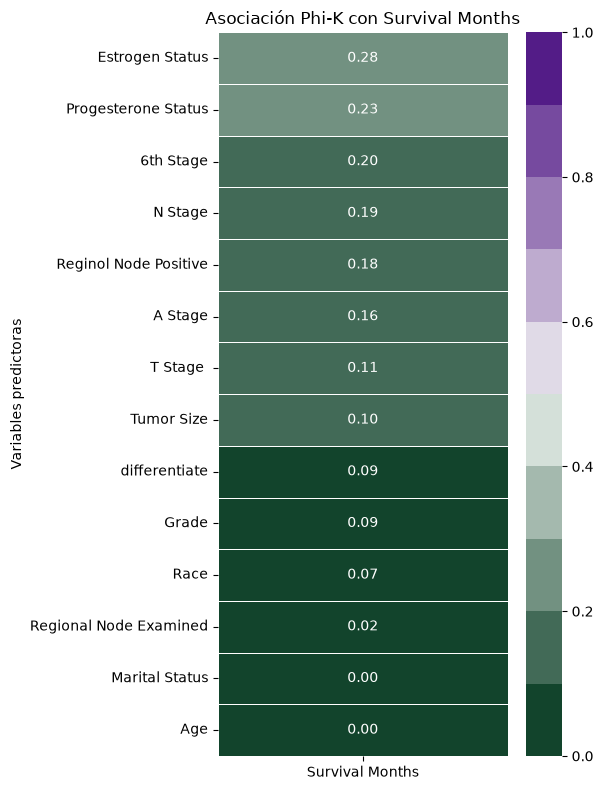

In [53]:
# Dataset de entrenamiento
df_train = pd.concat([X_train, y_train], axis=1)

# Matriz Phi-K
phik_matrix = df_train.phik_matrix()

# Asociación con la variable objetivo
phik_target = (
    phik_matrix['Survival Months']
    .drop('Survival Months')
    .sort_values(ascending=False)
)

# Heatmap
plt.figure(figsize=(6, 8))

sns.heatmap(
    phik_target.to_frame(),
    vmin=0,
    vmax=1,
    annot=True,
    fmt='.2f',
    cmap=sns.diverging_palette(
        145, 280,
        s=85,
        l=25,
        n=10
    ),
    linewidths=0.5
)

plt.title('Asociación Phi-K con Survival Months')
plt.xlabel('')
plt.ylabel('Variables predictoras')

plt.tight_layout()
plt.show()

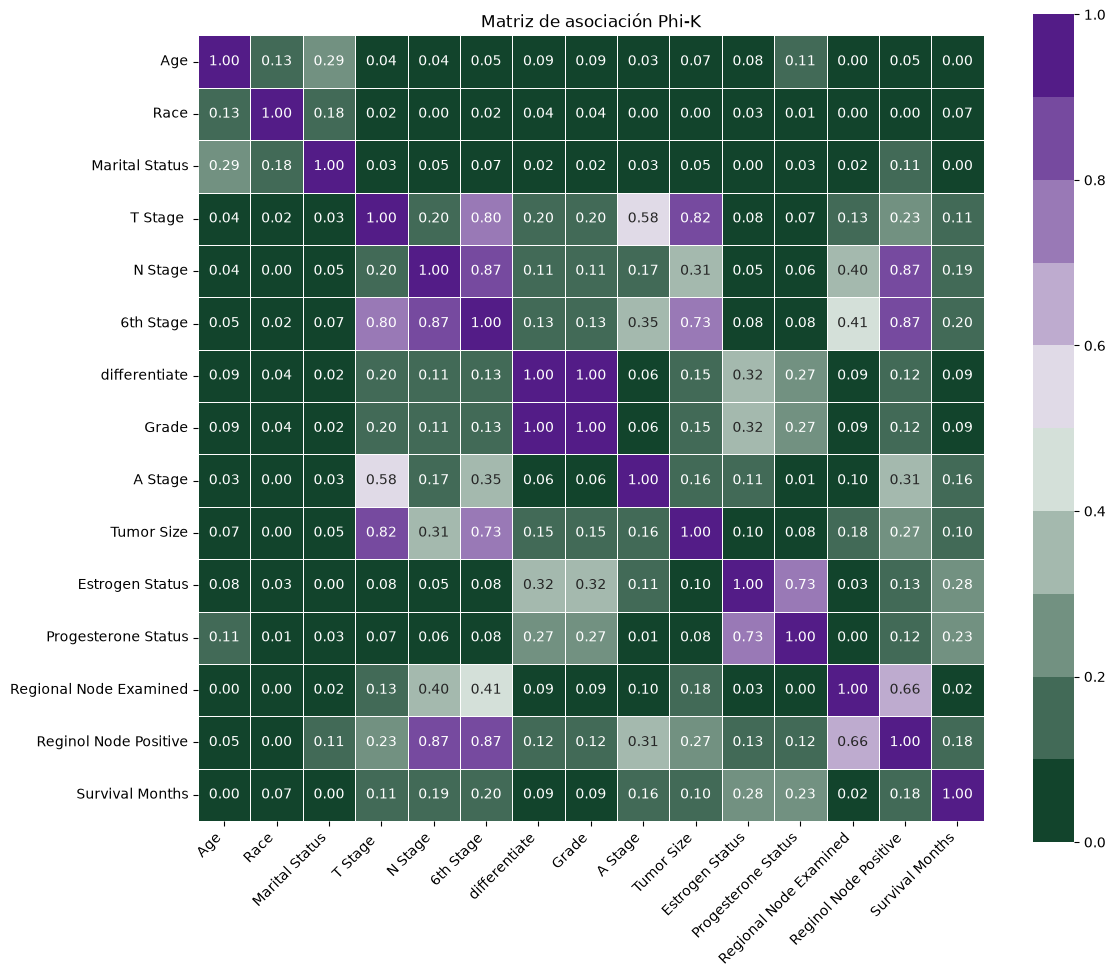

In [54]:
plt.figure(figsize=(12,10))

sns.heatmap(
    phik_matrix,
    vmin=0,
    vmax=1,
    annot=True,
    fmt='.2f',
    cmap=sns.diverging_palette(
        145, 280,
        s=85,
        l=25,
        n=10
    ),
    linewidths=0.5,
    square=True
)

plt.title('Matriz de asociación Phi-K')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

El heatmap completo de Phi-K, segunda gráfica, muestra que existen asociaciones elevadas entre varias variables relacionadas con el estadio y la progresión del cáncer. Destacan las fuertes relaciones entre N Stage y 6th Stage (0,87), N Stage y Reginol Node Positive (0,87), T Stage y Tumor Size (0,82) y T Stage y 6th Stage (0,80). Estas asociaciones son coherentes desde el punto de vista clínico, ya que describen diferentes aspectos de la extensión tumoral y ganglionar.

Por otro lado, el heatmap de asociación con la variable objetivo (Survival Months), primer gráfico, indica que ninguna variable presenta una asociación fuerte con la supervivencia de forma individual. Las mayores asociaciones corresponden a Estrogen Status (0,28), Progesterone Status (0,23) y 6th Stage (0,20), seguidas de N Stage (0,19) y Reginol Node Positive (0,18).

Combinando ambos gráficos, puede concluirse que las variables relacionadas con el estado hormonal son las que muestran una mayor relación directa con la supervivencia, mientras que las variables de estadiaje tumoral y afectación ganglionar presentan fuertes asociaciones entre sí pero una capacidad predictiva individual más limitada respecto a Survival Months. Esto sugiere que la supervivencia depende de la interacción de múltiples factores y no de una única variable aislada.

In [52]:
pd.crosstab(
    X_train['differentiate'],
    X_train['Grade']
)

Grade,anaplastic; Grade IV,1,2,3
differentiate,,,,
Moderately differentiated,0,0,1867,0
Poorly differentiated,0,0,0,893
Undifferentiated,16,0,0,0
Well differentiated,0,443,0,0


Tal y como explicamos en la introducción, Grade y differenciate aportaban la misma información. El análisis de contingencia entre las variables Grade y differentiate mostró una correspondencia uno a uno entre sus categorías. Asimismo, ambas variables presentaron idénticos valores de asociación PhiK respecto a la variable objetivo. Por tanto, queda comprobado que ambas dan información redundante y procedemos a eliminar una de ellas, differenciate, ya que Grade está como variable categórica ordinal.

In [55]:
X_train = X_train.drop(columns=['differentiate'])
X_test = X_test.drop(columns=['differentiate'])

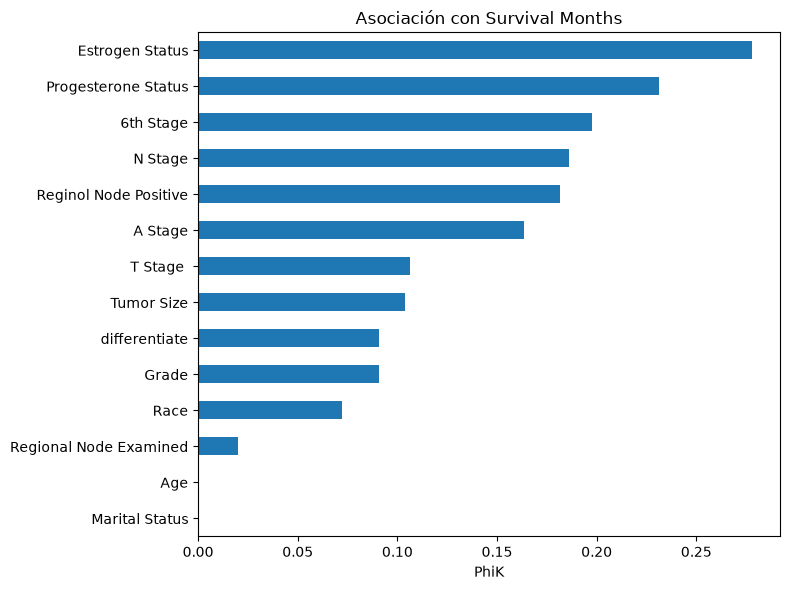

In [56]:
plt.figure(figsize=(8,6))

phik_target.sort_values().plot(kind='barh')

plt.xlabel('PhiK')
plt.title('Asociación con Survival Months')

plt.tight_layout()
plt.show()

- De las variables categóricas veamos cuales son las más importantes

In [57]:
# Codificación de variables categóricas
X_train_dummies = pd.get_dummies(X_train, drop_first=False)

# Entrenamiento
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

rf.fit(X_train_dummies, y_train)

# Importancias
importancias = pd.DataFrame({'Variable': X_train_dummies.columns, 'Importancia': rf.feature_importances_})

importancias = importancias.sort_values(by='Importancia', ascending=False)

# Agrupamos por las categorías originales

resultados = []

for var in X_train.columns:

    columnas = [
        col for col in X_train_dummies.columns
        if col == var or col.startswith(var + "_")
    ]

    importancia = importancias.loc[
        importancias['Variable'].isin(columnas),
        'Importancia'
    ].sum()

    resultados.append([var, importancia])

resultado_final = pd.DataFrame(
    resultados,
    columns=["Variable", "Importancia"]
)

resultado_final = resultado_final.sort_values(
    by="Importancia",
    ascending=False
)

print(resultado_final)

                  Variable  Importancia
0                      Age     0.210214
11  Regional Node Examined     0.197427
8               Tumor Size     0.193168
12   Reginol Node Positive     0.104342
2           Marital Status     0.075365
6                    Grade     0.064911
1                     Race     0.037944
10     Progesterone Status     0.029041
5                6th Stage     0.024447
9          Estrogen Status     0.021618
3                 T Stage      0.020940
4                  N Stage     0.013715
7                  A Stage     0.006869


Las cuatro variables más importantes acumulan aproximadamente el 70 % de la importancia total:

- Age: 21,0 %: es la variable más importante, aunque no implica una relación lineal con la supervivencia, como se vio anteriormente.
- Regional Node Examined: 19,7 %: esta variable sorprende que sea más importante que Reginol Node Positive. Aunque puede estar actuando como algún indicador indirecto como extensión de la cirugía por ejemplo.
- Tumor Size: 19,3 %: esta variable tienen una importancia muy alta y fue la segunda variable más importante cuando usamos el SelectKBest 
- Reginol Node Positive: 10,4 %: sigue siendo muy importante pero ha perdido peso por relativo porque su información se combina con otras variables.

Esto indica que el modelo está basando gran parte de sus predicciones en características cuantitativas relacionadas con la paciente y el tumor.

El análisis de importancia de variables mediante Random Forest mostró que la edad (21,0 %), el número de ganglios regionales examinados (19,7 %) y el tamaño tumoral (19,3 %) fueron los predictores más relevantes de la supervivencia. El número de ganglios positivos también presentó una contribución destacada (10,4 %). Entre las variables categóricas, el estado civil (7,5 %) y el grado histológico (6,5 %) mostraron una importancia moderada, mientras que los estadios TNM (T Stage, N Stage, 6th Stage y A Stage) tuvieron una contribución menor. Esta aparente contradicción con el conocimiento clínico puede explicarse porque variables como el tamaño tumoral y los ganglios positivos ya contienen gran parte de la información utilizada para construir los estadios clínicos, generando redundancia entre predictores. Por tanto, el modelo tiende a utilizar directamente las variables originales en lugar de las variables derivadas de estadio.

En conjunto, los resultados sugieren que la predicción de la supervivencia no depende de un único factor clínico, sino de la interacción de múltiples características demográficas, anatomo-patológicas y tumorales. Además, ponen de manifiesto la capacidad de los métodos basados en árboles para capturar relaciones complejas y no lineales entre las variables, identificando patrones predictivos que no siempre son detectados por técnicas de selección univariante. Por tanto, la combinación de variables relacionadas con la edad de la paciente, las características del tumor y la afectación ganglionar constituye la principal fuente de información para la estimación de la supervivencia en este conjunto de datos.